# Step 2: GNN sentence scorer + ablations
Trains a relational graph-attention network (one GATv2 attention block per edge type) to predict, for every sentence, whether the Step 0 oracle selected it.
The model is selected by **validation ROUGE of the summary built from its top-ranked sentences** (not by loss).

Runs 5 experiments x 3 seeds (resumable): `mlp_emb`, `mlp_feat` (no graph), `gnn_entity`, `gnn_ent_sem`, `gnn_full`.
Outputs go to `<BASE>/gnn/` : `runs/`, `models/`, `preds/` (sentence probabilities, used by Step 3), `figures/`, `results_table.csv`.

**Runtime: use a T4 GPU.** Edit the paths in cell 2 (same `BASE` as Steps 0 and 1).

In [1]:
!pip -q install torch_geometric rouge-score scikit-learn tqdm
from google.colab import drive
drive.mount('/content/drive')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive


In [2]:
import os, re, json, math, time, copy, random, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from tqdm.auto import tqdm
warnings.filterwarnings("ignore", category=FutureWarning)

# ============ EDIT THESE (same BASE as Steps 0 and 1) ============
BASE        = "/content/drive/MyDrive/inabs_project"
GRAPH_DIR   = f"{BASE}/graphs"      # output of Step 1
OUT_DIR     = f"{BASE}/gnn"         # output of this step
SPLIT_NAMES = ["train", "validate", "test"]
# ==================================================================

HP = dict(
    hidden=256, layers=2, heads=4, dropout=0.3,
    lr=5e-4, weight_decay=0.01, epochs=60, patience=12, batch_size=8, grad_clip=1.0,
    label_mode="binary",       # "binary" | "soft" | "mix"  (oracle y, soft ROUGE-2 recall, or their average)
    pos_weight_max=10.0,       # cap for the positive-class weight
    use_edge_weight=True,      # feed edge weights into the attention
)
SEEDS = [0, 1, 2]              # use [0] for a quick first run
COMPUTE_ROUGE_L = True         # official ROUGE-L on the test set (slower: ~0.5 s per document)
OVERWRITE_RUNS = False         # False = skip finished (experiment, seed) runs

# relation ids from Step 1: 0 = shared entity, 1 = semantic, 2 = sequential
EXPERIMENTS = {
    "mlp_emb":     dict(features="emb", graph=False, rels=[]),         # 1. embeddings only, no graph
    "mlp_feat":    dict(features="all", graph=False, rels=[]),         #    + position/section/entity features, no graph
    "gnn_entity":  dict(features="all", graph=True,  rels=[0]),        # 2. entity edges only
    "gnn_ent_sem": dict(features="all", graph=True,  rels=[0, 1]),     # 3. entity + semantic
    "gnn_full":    dict(features="all", graph=True,  rels=[0, 1, 2]),  # 4. entity + semantic + sequential
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for d in ("runs", "models", "preds", "figures"): Path(OUT_DIR, d).mkdir(parents=True, exist_ok=True)
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (works, just slower)")

device: cuda | Tesla T4


## 1. Load the graphs (the 460 documents) and standardise features

In [3]:
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

GR, by_split = [], {s: [] for s in SPLIT_NAMES}
for split in SPLIT_NAMES:
    for p in sorted(Path(GRAPH_DIR, split).glob("*.pt")):
        by_split[split].append(len(GR))
        GR.append(torch.load(p, map_location="cpu", weights_only=True))
print({s: len(v) for s, v in by_split.items()}, "graphs loaded")
assert all(len(v) > 0 for v in by_split.values()), "a split has no graphs - check GRAPH_DIR / Step 1"

EMB_DIM = GR[0]["emb_dim"]; IN_DIM_ALL = GR[0]["x"].shape[1]
assert all(g["x"].shape[1] == IN_DIM_ALL for g in GR), "feature dimension differs between graphs"

# z-score with TRAIN statistics only (no leakage); clamp unseen one-hot values
Xtr = torch.cat([GR[i]["x"] for i in by_split["train"]])
MU, SD = Xtr.mean(0), Xtr.std(0).clamp_min(1e-3)
del Xtr

def make_data(idx):
    g = GR[idx]
    return Data(x=((g["x"] - MU) / SD).clamp(-10, 10), edge_index=g["edge_index"], edge_type=g["edge_type"],
                edge_weight=g["edge_weight"], y=g["y"], y_soft=g["y_soft"],
                gid=torch.tensor([idx]), num_nodes=g["num_nodes"])
DATA = {s: [make_data(i) for i in by_split[s]] for s in SPLIT_NAMES}

ytr = torch.cat([GR[i]["y"] for i in by_split["train"]])
POS_RATE = float(ytr.mean()); POS_WEIGHT = float(min(max((1 - POS_RATE) / max(POS_RATE, 1e-6), 1.0), HP["pos_weight_max"]))
print(f"train positives: {POS_RATE:.1%} of sentences -> pos_weight {POS_WEIGHT:.2f}")

# summary length budget = mean reference length (words) of the TRAIN set
BUDGET = int(np.mean([len(GR[i]["reference"].split()) for i in by_split["train"]]))
WORDS = {i: g["sent_words"].tolist() for i, g in enumerate(GR)}
print("summary budget:", BUDGET, "words")
torch.save(dict(mu=MU, sd=SD, budget=BUDGET), Path(OUT_DIR, "preproc.pt"))

{'train': 300, 'validate': 60, 'test': 100} graphs loaded
train positives: 17.9% of sentences -> pos_weight 4.58
summary budget: 898 words


## 2. Evaluation machinery
Validation uses a fast ROUGE-1/2 (cached n-gram counts, same tokenizer/stemmer as `rouge-score`). The final test numbers use the official `rouge-score` package.

In [4]:
from rouge_score import rouge_scorer, tokenizers
from sklearn.metrics import roc_auc_score

TOK = tokenizers.DefaultTokenizer(use_stemmer=True)
class _CachedStemmer:                         # speeds up stemming ~10x; identical output
    def __init__(self, st): self.st, self.c = st, {}
    def stem(self, w):
        r = self.c.get(w)
        if r is None: r = self.c[w] = self.st.stem(w)
        return r
if getattr(TOK, "_stemmer", None) is not None: TOK._stemmer = _CachedStemmer(TOK._stemmer)

def ngr(t, n): return Counter(zip(*[t[i:] for i in range(n)])) if len(t) >= n else Counter()
def f1(ov, ct, rt):
    if ov <= 0 or ct <= 0 or rt <= 0: return 0.0
    p, r = ov / ct, ov / rt
    return 2 * p * r / (p + r)

CACHE = {}
for idx, g in enumerate(tqdm(GR, desc="caching n-grams")):
    rt = TOK.tokenize(g["reference"]); r1, r2 = ngr(rt, 1), ngr(rt, 2)
    c1, c2, L1, L2 = [], [], [], []
    for s in g["sentences"]:
        t = TOK.tokenize(s); a, b = ngr(t, 1), ngr(t, 2)
        c1.append(Counter({k: v for k, v in a.items() if k in r1})); c2.append(Counter({k: v for k, v in b.items() if k in r2}))
        L1.append(len(t)); L2.append(max(len(t) - 1, 0))
    CACHE[idx] = dict(r1=r1, r2=r2, R1=len(rt), R2=max(len(rt) - 1, 0), c1=c1, c2=c2, L1=L1, L2=L2)

def fast_rouge(idx, sel):
    d = CACHE[idx]; s1, s2, t1, t2 = Counter(), Counter(), 0, 0
    for i in sel: s1.update(d["c1"][i]); s2.update(d["c2"][i]); t1 += d["L1"][i]; t2 += d["L2"][i]
    ov1 = sum(min(c, d["r1"][k]) for k, c in s1.items()); ov2 = sum(min(c, d["r2"][k]) for k, c in s2.items())
    return f1(ov1, t1, d["R1"]), f1(ov2, t2, d["R2"])

def select_topk(scores, words, budget):
    """highest-scoring sentences until the word budget is reached, returned in document order"""
    chosen, w = [], 0
    for i in np.argsort(-np.asarray(scores)):
        chosen.append(int(i)); w += words[i]
        if w >= budget: break
    return sorted(chosen)

def evaluate(idxs, selector, probs=None, official=False):
    r1s, r2s, prec, nw = [], [], [], []
    off = {"rouge1": [], "rouge2": [], "rougeL": []}
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2"] + (["rougeL"] if COMPUTE_ROUGE_L else []), use_stemmer=True) if official else None
    for i in idxs:
        g, sel = GR[i], selector(i)
        a, b = fast_rouge(i, sel); r1s.append(a); r2s.append(b)
        orc = set(g["oracle_idx"]); prec.append(len(orc & set(sel)) / max(len(sel), 1))
        nw.append(sum(WORDS[i][j] for j in sel))
        if official:
            sc = scorer.score(g["reference"], " ".join(g["sentences"][j] for j in sel))
            for k in sc: off[k].append(sc[k].fmeasure)
    out = dict(fast_r1=float(np.mean(r1s)), fast_r2=float(np.mean(r2s)), score=float((np.mean(r1s) + np.mean(r2s)) / 2),
               oracle_precision=float(np.mean(prec)), avg_words=float(np.mean(nw)))
    if probs is not None:
        y = np.concatenate([GR[i]["y"].numpy() for i in idxs]); p = np.concatenate([probs[i].numpy() for i in idxs])
        out["auroc"] = float(roc_auc_score(y, p)) if 0 < y.sum() < len(y) else float("nan")
    if official: out.update({k: float(np.mean(v)) for k, v in off.items() if v})
    return out

# ---- reference rows for the results table: Lead (first sentences) and Oracle (upper bound)
lead   = lambda i: select_topk(np.arange(len(WORDS[i]))[::-1], WORDS[i], BUDGET)
oracle = lambda i: sorted(GR[i]["oracle_idx"])
BASELINES = {}
for name, sel in (("Lead (first sentences)", lead), ("Oracle (upper bound)", oracle)):
    BASELINES[name] = evaluate(by_split["test"], sel, official=True)
    print(f"{name:24s} test  R1 {BASELINES[name]['rouge1']:.4f}  R2 {BASELINES[name]['rouge2']:.4f}" + (f"  RL {BASELINES[name]['rougeL']:.4f}" if COMPUTE_ROUGE_L else ""))

caching n-grams:   0%|          | 0/460 [00:00<?, ?it/s]

Lead (first sentences)   test  R1 0.5263  R2 0.3064  RL 0.2912
Oracle (upper bound)     test  R1 0.7103  R2 0.5330  RL 0.4659


## 3. Model and training loop

In [5]:
from torch_geometric.nn import GATv2Conv

class RelGATLayer(nn.Module):
    """Relational graph attention: one multi-head GATv2 attention block per edge type (entity / semantic /
    sequential) + a self transform, summed. Same idea as RGAT (attention inside each relation, separate
    parameters per relation) but memory is linear in the number of edges."""
    def __init__(self, h, heads, rels, use_ew):
        super().__init__()
        self.rels, self.use_ew = list(rels), use_ew
        self.root = nn.Linear(h, h)
        self.convs = nn.ModuleList([GATv2Conv(h, h // heads, heads=heads, edge_dim=1 if use_ew else None, fill_value=1.0)
                                    for _ in self.rels])
    def forward(self, h, edge_index, edge_type, edge_weight):
        out = self.root(h)
        for r, conv in zip(self.rels, self.convs):
            m = edge_type == r
            out = out + conv(h, edge_index[:, m], edge_attr=edge_weight[m].unsqueeze(-1) if self.use_ew else None)
        return out

class Scorer(nn.Module):
    def __init__(self, in_dim, spec, hp):
        super().__init__()
        h, p = hp["hidden"], hp["dropout"]
        self.spec, self.p = spec, p
        self.feat_cols = EMB_DIM if spec["features"] == "emb" else None
        self.inp = nn.Sequential(nn.Linear(in_dim, h), nn.GELU(), nn.Dropout(p))
        self.layers, self.norms = nn.ModuleList(), nn.ModuleList()
        if spec["graph"]:
            for _ in range(hp["layers"]):
                self.layers.append(RelGATLayer(h, hp["heads"], spec["rels"], hp["use_edge_weight"]))
                self.norms.append(nn.LayerNorm(h))
        self.out = nn.Sequential(nn.Linear(h, h // 2), nn.GELU(), nn.Dropout(p), nn.Linear(h // 2, 1))

    def forward(self, d):
        x = d.x[:, :self.feat_cols] if self.feat_cols else d.x
        h = self.inp(x)
        for layer, nm in zip(self.layers, self.norms):
            h = nm(h + F.dropout(F.gelu(layer(h, d.edge_index, d.edge_type, d.edge_weight)), self.p, self.training))
        return self.out(h).squeeze(-1)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def in_dim_for(spec): return EMB_DIM if spec["features"] == "emb" else IN_DIM_ALL

def targets(b):
    m = HP["label_mode"]
    return b.y if m == "binary" else b.y_soft if m == "soft" else 0.5 * (b.y + b.y_soft)

@torch.no_grad()
def predict(model, data_list, bs=16):
    model.eval(); out = {}
    for b in DataLoader(data_list, batch_size=bs, shuffle=False):
        b = b.to(device); pr = torch.sigmoid(model(b)).cpu(); ptr = b.ptr.cpu(); gid = b.gid.cpu()
        for k in range(len(ptr) - 1): out[int(gid[k])] = pr[ptr[k]:ptr[k + 1]].clone()
    return out

def run_experiment(name, spec, seed):
    set_seed(seed)
    model = Scorer(in_dim_for(spec), spec, HP).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT, device=device))
    g = torch.Generator(); g.manual_seed(seed)
    loader = DataLoader(DATA["train"], batch_size=HP["batch_size"], shuffle=True, generator=g)
    val_idx = by_split["validate"]
    best, best_state, best_ep, hist, t0 = -1.0, None, 0, [], time.time()

    for ep in range(1, HP["epochs"] + 1):
        model.train(); tot = cnt = 0
        for b in loader:
            b = b.to(device); opt.zero_grad()
            loss = lossf(model(b), targets(b))
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), HP["grad_clip"]); opt.step()
            tot += loss.item() * b.num_nodes; cnt += b.num_nodes
        vp = predict(model, DATA["validate"])
        vm = evaluate(val_idx, lambda i: select_topk(vp[i].numpy(), WORDS[i], BUDGET), probs=vp)
        hist.append(dict(epoch=ep, train_loss=tot / cnt, val_score=vm["score"], val_auroc=vm["auroc"]))
        if vm["score"] > best + 1e-4:
            best, best_ep, best_state = vm["score"], ep, copy.deepcopy(model.state_dict())
        if ep % 10 == 0 or ep == 1:
            print(f"  [{name} s{seed}] ep {ep:2d}  loss {tot / cnt:.4f}  val R1/R2 score {vm['score']:.4f}  auroc {vm['auroc']:.3f}  (best {best:.4f} @ {best_ep})")
        if ep - best_ep >= HP["patience"]:
            print(f"  [{name} s{seed}] early stop at epoch {ep}"); break

    model.load_state_dict(best_state)
    preds = {s: predict(model, DATA[s]) for s in SPLIT_NAMES}
    res = {}
    for s in ("validate", "test"):
        res[s] = evaluate(by_split[s], lambda i, s=s: select_topk(preds[s][i].numpy(), WORDS[i], BUDGET), probs=preds[s], official=(s == "test"))
    torch.save({"state": model.state_dict(), "spec": spec, "hp": HP, "in_dim": in_dim_for(spec)}, Path(OUT_DIR, "models", f"{name}_seed{seed}.pt"))
    torch.save({s: {GR[i]["doc_id"]: preds[s][i] for i in by_split[s]} for s in SPLIT_NAMES}, Path(OUT_DIR, "preds", f"{name}_seed{seed}.pt"))
    run = dict(name=name, seed=seed, spec=spec, hp=HP, budget=BUDGET, best_epoch=best_ep, epochs_run=len(hist),
               val=res["validate"], test=res["test"], history=hist, seconds=round(time.time() - t0, 1))
    json.dump(run, open(Path(OUT_DIR, "runs", f"{name}_seed{seed}.json"), "w"), indent=1)
    return run

# ---- smoke test: one forward + backward pass per experiment type BEFORE the long run
def smoke_test():
    b = next(iter(DataLoader(DATA["train"][:4], batch_size=4))).to(device)
    for name, spec in EXPERIMENTS.items():
        m = Scorer(in_dim_for(spec), spec, HP).to(device); out = m(b)
        assert out.shape[0] == b.num_nodes and torch.isfinite(out).all(), name
        nn.BCEWithLogitsLoss()(out, b.y).backward()
    print("smoke test passed for", list(EXPERIMENTS))
try:
    smoke_test()
except Exception as e:
    if HP["use_edge_weight"]:
        print(f"edge-weight attention failed ({type(e).__name__}: {e}); retrying without it")
        HP["use_edge_weight"] = False; smoke_test()
    else: raise
n_params = {k: sum(p.numel() for p in Scorer(in_dim_for(s), s, HP).parameters()) for k, s in EXPERIMENTS.items()}
print("parameters:", n_params)

smoke test passed for ['mlp_emb', 'mlp_feat', 'gnn_entity', 'gnn_ent_sem', 'gnn_full']
parameters: {'mlp_emb': 229889, 'mlp_feat': 236545, 'gnn_entity': 633857, 'gnn_ent_sem': 898561, 'gnn_full': 1163265}


## 4. Run all experiments (resumable; each finished run is saved immediately)

In [6]:
def load_if_done(name, spec, seed):
    f = Path(OUT_DIR, "runs", f"{name}_seed{seed}.json")
    if OVERWRITE_RUNS or not f.exists(): return None
    r = json.load(open(f))
    same = (r["hp"] == json.loads(json.dumps(HP)) and r["spec"] == json.loads(json.dumps(spec)) and r["budget"] == BUDGET)
    return r if same else None

RUNS = []
t_all = time.time()
for name, spec in EXPERIMENTS.items():
    for seed in SEEDS:
        r = load_if_done(name, spec, seed)
        if r is None:
            print(f"\n=== {name} | seed {seed} ===")
            r = run_experiment(name, spec, seed)
            print(f"  -> best epoch {r['best_epoch']} | val {r['val']['score']:.4f} | test R1 {r['test']['rouge1']:.4f} R2 {r['test']['rouge2']:.4f} | {r['seconds']:.0f}s")
        else:
            print(f"=== {name} | seed {seed}: already done, skipped ===")
        RUNS.append(r)
print(f"\nall runs finished in {(time.time() - t_all) / 60:.1f} min")


=== mlp_emb | seed 0 ===
  [mlp_emb s0] ep  1  loss 1.0948  val R1/R2 score 0.4407  auroc 0.695  (best 0.4407 @ 1)
  [mlp_emb s0] ep 10  loss 0.7931  val R1/R2 score 0.4313  auroc 0.687  (best 0.4407 @ 1)
  [mlp_emb s0] ep 20  loss 0.5190  val R1/R2 score 0.4339  auroc 0.675  (best 0.4443 @ 11)
  [mlp_emb s0] early stop at epoch 23
  -> best epoch 11 | val 0.4443 | test R1 0.5618 R2 0.3555 | 34s

=== mlp_emb | seed 1 ===
  [mlp_emb s1] ep  1  loss 1.0936  val R1/R2 score 0.4412  auroc 0.689  (best 0.4412 @ 1)
  [mlp_emb s1] ep 10  loss 0.7902  val R1/R2 score 0.4429  auroc 0.693  (best 0.4436 @ 9)
  [mlp_emb s1] ep 20  loss 0.5320  val R1/R2 score 0.4395  auroc 0.676  (best 0.4467 @ 19)
  [mlp_emb s1] ep 30  loss 0.3826  val R1/R2 score 0.4398  auroc 0.673  (best 0.4467 @ 19)
  [mlp_emb s1] early stop at epoch 31
  -> best epoch 19 | val 0.4467 | test R1 0.5667 R2 0.3626 | 34s

=== mlp_emb | seed 2 ===
  [mlp_emb s2] ep  1  loss 1.0918  val R1/R2 score 0.4414  auroc 0.688  (best 0.441

## 5. Results table (mean ± std over seeds) = your ablation table

In [7]:
import pandas as pd
LABELS = {"mlp_emb": "MLP, embeddings only (no graph)", "mlp_feat": "MLP, embeddings + node features (no graph)",
          "gnn_entity": "GNN, entity edges", "gnn_ent_sem": "GNN, entity + semantic edges",
          "gnn_full": "GNN, entity + semantic + sequential (full)"}
def ms(v, pct=True):
    v = np.array(v) * (100 if pct else 1)
    return f"{v.mean():.2f} ± {v.std():.2f}" if len(v) > 1 else f"{v.mean():.2f}"

rows = []
for name in EXPERIMENTS:
    rs = [r for r in RUNS if r["name"] == name]
    row = {"Model": LABELS[name], "Val score": ms([r["val"]["score"] for r in rs]),
           "Test R-1": ms([r["test"]["rouge1"] for r in rs]), "Test R-2": ms([r["test"]["rouge2"] for r in rs])}
    if COMPUTE_ROUGE_L: row["Test R-L"] = ms([r["test"]["rougeL"] for r in rs])
    row["AUROC"] = ms([r["test"]["auroc"] for r in rs], pct=False)
    row["Oracle-hit"] = ms([r["test"]["oracle_precision"] for r in rs])
    rows.append(row)
for name, m in BASELINES.items():
    row = {"Model": name, "Val score": "-", "Test R-1": f"{m['rouge1']*100:.2f}", "Test R-2": f"{m['rouge2']*100:.2f}"}
    if COMPUTE_ROUGE_L: row["Test R-L"] = f"{m['rougeL']*100:.2f}"
    row["AUROC"] = "-"; row["Oracle-hit"] = "-"
    rows.append(row)
TABLE = pd.DataFrame(rows)
TABLE.to_csv(Path(OUT_DIR, "results_table.csv"), index=False)
print(TABLE.to_string(index=False))
print("\nVal score = (ROUGE-1 + ROUGE-2)/2 on the validation set (used for early stopping).")
print("Oracle-hit = share of selected sentences that the oracle also selected.  AUROC = sentence-level ranking quality.")

# the run Step 3 should use: best validation score among the full-graph seeds
full = [r for r in RUNS if r["name"] == "gnn_full"]
best_full = max(full, key=lambda r: r["val"]["score"])
json.dump(dict(name="gnn_full", seed=best_full["seed"], val_score=best_full["val"]["score"],
               preds=f"preds/gnn_full_seed{best_full['seed']}.pt", budget=BUDGET),
          open(Path(OUT_DIR, "best_run.json"), "w"), indent=1)
print(f"\nbest full-graph run for Step 3: seed {best_full['seed']} (saved in best_run.json)")

                                     Model    Val score     Test R-1     Test R-2     Test R-L       AUROC   Oracle-hit
           MLP, embeddings only (no graph) 44.52 ± 0.11 56.43 ± 0.20 35.90 ± 0.29 32.54 ± 0.20 0.67 ± 0.00 36.68 ± 1.49
MLP, embeddings + node features (no graph) 44.22 ± 0.20 56.24 ± 0.56 35.88 ± 0.56 32.48 ± 0.64 0.70 ± 0.01 41.20 ± 1.35
                         GNN, entity edges 43.82 ± 0.05 56.21 ± 0.31 35.65 ± 0.32 32.19 ± 0.11 0.69 ± 0.02 40.81 ± 3.13
              GNN, entity + semantic edges 44.04 ± 0.18 55.94 ± 0.08 35.33 ± 0.18 32.00 ± 0.21 0.71 ± 0.01 41.72 ± 2.54
GNN, entity + semantic + sequential (full) 44.40 ± 0.13 56.22 ± 0.34 35.96 ± 0.05 32.43 ± 0.09 0.71 ± 0.01 40.24 ± 0.90
                    Lead (first sentences)            -        52.63        30.64        29.12           -            -
                      Oracle (upper bound)            -        71.03        53.30        46.59           -            -

Val score = (ROUGE-1 + ROUGE-2)/2 on th

## 6. Training curves

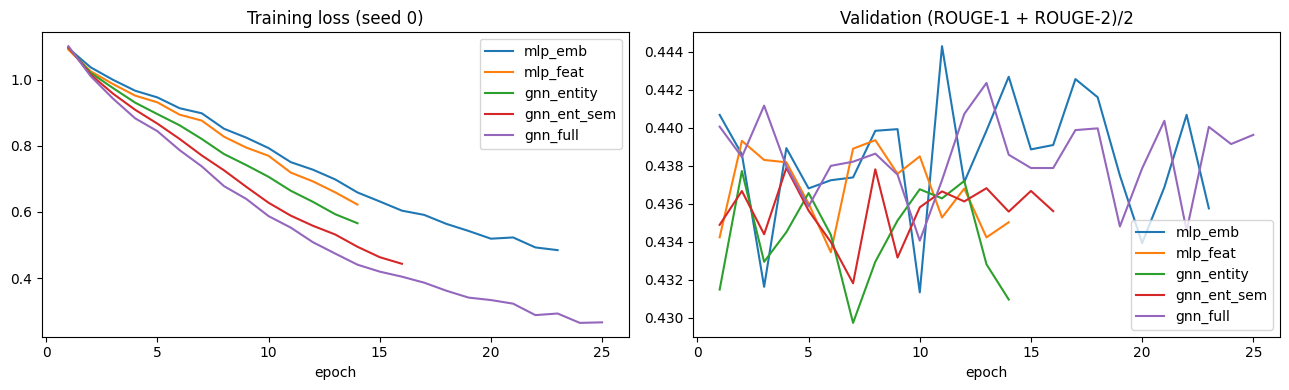

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name in EXPERIMENTS:
    r = next(r for r in RUNS if r["name"] == name and r["seed"] == SEEDS[0])
    ep = [h["epoch"] for h in r["history"]]
    ax[0].plot(ep, [h["train_loss"] for h in r["history"]], label=name)
    ax[1].plot(ep, [h["val_score"] for h in r["history"]], label=name)
ax[0].set_title("Training loss (seed %d)" % SEEDS[0]); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Validation (ROUGE-1 + ROUGE-2)/2"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(Path(OUT_DIR, "figures", "training_curves.png"), dpi=130); plt.show()

## 7. Look at what the model picks (one test document)

In [9]:
i = by_split["test"][0]; g = GR[i]
P = torch.load(Path(OUT_DIR, "preds", f"gnn_full_seed{best_full['seed']}.pt"), weights_only=True)["test"][g["doc_id"]].numpy()
sel = select_topk(P, WORDS[i], BUDGET); orc = set(g["oracle_idx"])
print(f"{g['doc_id']}: {g['num_nodes']} sentences | selected {len(sel)} | {len(orc & set(sel))} of them are oracle sentences\n")
for j in sorted(sel, key=lambda k: -P[k])[:6]:
    print(f"[{j}] p={P[j]:.2f} {'(oracle)' if j in orc else '        '} {g['sentences'][j][:160]}")

test_1038: 43 sentences | selected 22 | 4 of them are oracle sentences

[38] p=0.87          On a proper interpretation of the section it only means that the exemption under the licence is conditional upon the observance of the conditions prescribed and
[21] p=0.87 (oracle) The High Court has held that on a true interpretation of the provisions of the Act and the rules made thereunder, the observance of conditions of the license wa
[9] p=0.84 (oracle) They obtained a license under section 5 of the Madras General Sales Tax Act (Act IX of 1939), hereinafter referred to as the 'Act '.
[34] p=0.79          5 of the General Sales Tax Rules which provided 741 that if any person desired to avail himself of the exemption provided in section 5, he had to submit an appl
[29] p=0.74 (oracle) R. 8 "Every licence granted or renewed under these rules shall be liable to cancellation by the Deputy Commercial Tax Officer in the event of a breach of any of
[41] p=0.72          In that view of the matter